# MODELOS Y SIMULACIÓN - 2026

## Trabajo Práctico 6: Modelo de Cole

En este trabajo se usa **la fórmula del PDF**, conservando el signo menos del denominador en la implementación, las simulaciones y los ajustes:

$$Z(f)=R_\infty+\frac{R_0-R_\infty}{1-(j2\pi f\tau)^\alpha}
=R_\infty+\frac{R_0-R_\infty}{1-(jf/f_c)^\alpha}.$$

Se utilizó Python con NumPy, SciPy, Pandas y Matplotlib dentro del entorno `.conda-env` del repositorio. El notebook incluye controles interactivos con `ipywidgets`.

### Aclaración sobre los signos

La expresión impresa en el PDF tiene un menos exterior en el denominador. La forma habitual de Cole en la bibliografía tiene un más: $1+(j\omega\tau)^\alpha$. Son expresiones diferentes para exponentes fraccionarios. Aquí se sigue la consigna literalmente; la forma con más queda disponible únicamente para comparación en el explorador y en una figura complementaria. No se afirma que la cátedra haya confirmado una errata.

También hay que distinguir dos signos de la representación: $\operatorname{Im}(Z)$ es la reactancia calculada, mientras $-\operatorname{Im}(Z)$ es una forma de dibujar el eje vertical del plano de Cole. Graficar su negativo no cambia el modelo. Tampoco se cambia el signo de las mediciones para hacerlas coincidir con la ecuación.

Cambiar la convención temporal conjugando la impedancia reemplaza $j$ por $-j$ dentro de la potencia. En general, no equivale a reemplazar un más exterior por un menos exterior.


## Preparación

Usar el kernel Python (MyS) del entorno `.conda-env` y ejecutar las celdas en orden. La primera celda muestra el intérprete utilizado.

In [11]:
from pathlib import Path
import sys
import importlib
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = next((p for p in [Path.cwd(), Path.cwd()/'trabajos'/'Tp6'] if (p/'cole.py').exists()), None)
if BASE is None:
    raise FileNotFoundError('Abrir Jupyter desde la raíz del repo o desde trabajos/Tp6.')
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
import cole as tp
importlib.reload(tp)
(BASE/'resultados').mkdir(exist_ok=True)
print('Intérprete:', sys.executable)
print('Fórmula del trabajo: signo menos del PDF.')

Intérprete: /home/ro/Desktop/facu/MyS/MySss/.conda-env/bin/python
Fórmula del trabajo: signo menos del PDF.


## Punto 1: Implementación del modelo del PDF

La impedancia es una cantidad compleja:

$$Z(f)=R(f)+jX(f),\qquad j^2=-1.$$

La parte real es la resistencia y la parte imaginaria es la reactancia. Se calculan además el módulo $|Z|=\sqrt{R^2+X^2}$ y la fase $\varphi=\operatorname{atan2}(X,R)$.

| Parámetro | Interpretación en el modelo | Unidad |
|---|---|---|
| $R_0$ | Límite resistivo cuando la frecuencia tiende a cero | Ω |
| $R_\infty$ | Límite resistivo cuando la frecuencia tiende a infinito | Ω |
| $f_c$ | Frecuencia característica | Hz |
| $\tau$ | Constante de tiempo, $1/(2\pi f_c)$ | s |
| $\alpha$ | Exponente fraccionario que modifica la dispersión | Sin unidad |

Como $\omega=2\pi f$ y $\tau=1/(2\pi f_c)$, se cumple $\omega\tau=f/f_c$. La implementación usa `(1j*f/fc_hz)**alpha`; `1j` es la unidad imaginaria. Los valores de $f_c$ en kHz se multiplican por 1000. Se conserva el exponente $\alpha$ del PDF, sin sustituirlo por $1-\alpha$.

La función `cole` admite una frecuencia o un vector y devuelve la impedancia compleja. Su valor predeterminado es `signo=-1`. Se exige $R_0>R_\infty\geq0$, $f_c>0$ y $0<\alpha\leq1$.

### Qué comportamiento produce esta fórmula

Definiendo $\Delta R=R_0-R_\infty$, $u=(f/f_c)^\alpha$ y $\theta=\alpha\pi/2$, la fórmula del PDF se separa como:

$$R(f)=R_\infty+\Delta R\frac{1-u\cos\theta}{1-2u\cos\theta+u^2},$$

$$X(f)=\Delta R\frac{u\sin\theta}{1-2u\cos\theta+u^2}.$$

Se conservan los límites $Z(0)=R_0$ y $Z(f\to\infty)=R_\infty$. Sin embargo, para frecuencia positiva y estos parámetros, **la reactancia calculada es positiva**. La resistencia puede sobrepasar los límites e incluso tomar valores negativos. Por eso no se puede trasladar sin más la interpretación capacitiva de la variante con signo más.

En $f=f_c$ se cumple:

$$R(f_c)=\frac{R_0+R_\infty}{2},\qquad
X(f_c)=\frac{\Delta R}{2}\cot\left(\frac{\alpha\pi}{4}\right).$$

El máximo de $X$ ocurre en $f_c$: al derivar $u/(1-2u\cos\theta+u^2)$, el numerador de la derivada es proporcional a $1-u^2$ y se anula en $u=1$. Al disminuir $\alpha$, aumenta la altura del máximo de la fórmula literal. Para $\alpha=1$, el arco es un semicírculo con reactancia positiva; en el gráfico de $-X$ aparece debajo del eje horizontal.

### Comprobaciones de la implementación

Se verifican los límites, la parte real y la reactancia en $f_c$, y el signo positivo de la reactancia. Además, se genera una curva sintética con parámetros conocidos $(500\ \Omega,80\ \Omega,40000\ \mathrm{Hz},0.65)$ usando la fórmula del PDF y se recuperan los cuatro parámetros mediante el ajuste, con tolerancia relativa $10^{-5}$. Esto verifica el cálculo, sin garantizar que las mediciones reales sigan esa ecuación.


In [12]:
print(inspect.getsource(tp.cole))
print(tp.verificar_modelo())
f = np.array([0., 37000., 1e12])
z = tp.cole(f, 385, 70, 37000, 0.27)  # signo=-1 por defecto
assert tp.cole(37000, 385, 70, 37000, 0.27).imag > 0
display(pd.DataFrame({'f_Hz': f, 'Re_Z_ohm': z.real, 'Im_Z_ohm': z.imag}))

def cole(f_hz, R0, Rinf, fc_hz, alpha, signo=-1):
    """Impedancia en Ω. Por defecto usa el signo menos del PDF.

    signo=+1 se conserva sólo para comparar con la forma habitual.

    Se usa el exponente alpha de la consigna, sin reemplazarlo por 1-alpha.
    NumPy evalúa la potencia compleja en su rama principal.
    """
    f = np.asarray(f_hz, dtype=float)
    if np.any(~np.isfinite(f)) or np.any(f < 0):
        raise ValueError("Las frecuencias deben ser finitas y no negativas.")
    if not all(np.isfinite([R0, Rinf, fc_hz, alpha])):
        raise ValueError("Los parámetros deben ser finitos.")
    if not (R0 > Rinf >= 0 and fc_hz > 0 and 0 < alpha <= 1):
        raise ValueError("Se requiere R0 > Rinf >= 0, fc > 0 y 0 < alpha <= 1.")
    if signo not in (-1, 1):
        raise ValueError("signo debe ser +1 o -1.")
    # omega*tau = (2*pi*f)/(2*pi*fc) = f/fc.
    return Rinf + (R0 - Rinf) / (1 + signo * (1j * f / fc_hz) ** alpha)

Verificados: límites, signo, valor en fc y recupe

,f_Hz,Re_Z_ohm,Im_Z_ohm
0,0.000000e+00,385.000000,0.000000
1,3.700000e+04,227.500000,731.556530
2,1.000000e+12,67.151988,1.299976


## Explorador interactivo del modelo de Cole

Ejecutar la celda del explorador y mover los controles: las curvas se actualizan **al soltar cada deslizador**. Se necesita un kernel activo.

- **Cargar tejido:** elige los parámetros de uno de los cinco tejidos del TP. La curva gris conserva ese caso como referencia con la fórmula del PDF.
- **R₀ y R∞:** controlan los parámetros resistivos; el máximo de R∞ se adapta para mantener $R_\infty<R_0$.
- **fc [Hz]:** recorre de 1 Hz a 10 MHz con escala logarítmica. El panel muestra también kHz y calcula $\tau$ automáticamente. **37000 Hz = 37 kHz**.
- **α:** modifica la forma y la altura del arco.
- **Fórmula:** empieza en **Consigna literal: signo −**. Opcionalmente permite comparar la forma con más.
- **Restablecer tejido:** recupera los cuatro parámetros del tejido elegido.

Para explorar, aumentar $f_c$ diez veces y observar el desplazamiento horizontal de los espectros. Luego restablecer y cambiar $\alpha$ para ver cómo se modifica el arco. Los puntos marcan la frecuencia característica. En el plano de Cole se grafica $-\operatorname{Im}(Z)$, de modo que el arco de la fórmula del PDF queda debajo del eje.

Los cambios del panel no modifican los parámetros guardados ni los resultados del informe.


In [ ]:
import cole_interactivo
importlib.reload(cole_interactivo)
explorador_cole, controles_cole = cole_interactivo.crear_explorador()
display(explorador_cole)

## Punto 2: Simulación de los cinco tejidos

Se utilizaron los parámetros del enunciado:

| Tejido | R₀ [Ω] | R∞ [Ω] | fc [kHz] | α | τ [µs] |
|---|---:|---:|---:|---:|---:|
| Músculo longitudinal | 385 | 70 | 37 | 0.27 | 4.3015 |
| Músculo transversal | 730 | 75 | 27 | 0.24 | 5.8946 |
| Hígado | 540 | 100 | 72 | 0.45 | 2.2105 |
| Pulmón | 440 | 70 | 100 | 0.59 | 1.5915 |
| Bazo | 550 | 60 | 373 | 0.36 | 0.4267 |

Los cinco tejidos se evaluaron sobre el mismo vector de 1600 frecuencias logarítmicas entre 1 Hz y 1 GHz, usando el signo menos del PDF. El rango amplio explora la ecuación; no implica validez física de un modelo de una dispersión en toda esa banda.


Las curvas muestran reactancia positiva y picos alrededor de cada $f_c$. El músculo transversal tiene el menor $f_c$ y el bazo el mayor. Los valores pequeños de $\alpha$ generan máximos importantes en esta expresión. Los valores negativos de resistencia que aparecen en algunas bandas son resultados de la ecuación literal, y no deben presentarse como propiedades físicas verificadas de esos tejidos.

En $f_c$, la resistencia vale 227.5, 402.5, 320, 255 y 305 Ω para los tejidos en el orden de la tabla. La resistencia no tiene por qué disminuir de manera monótona entre sus límites cuando se usa el signo menos.


El plano complejo muestra $-X$ contra $R$, por lo que los arcos aparecen debajo del eje. Los puntos marcan $f_c$. Se amplió la banda a $10^{-4}$–$10^{13}$ Hz para explorar mejor los extremos matemáticos, sin atribuir validez experimental a todo ese intervalo.


,tejido,R0_ohm,Rinf_ohm,fc_kHz,alpha,tau_us
0,Músculo longitudinal,385,70,37,0.27,4.301485
1,Músculo transversal,730,75,27,0.24,5.894628
2,Hígado,540,100,72,0.45,2.210485
3,Pulmón,440,70,100,0.59,1.591549
4,Bazo,550,60,373,0.36,0.426689


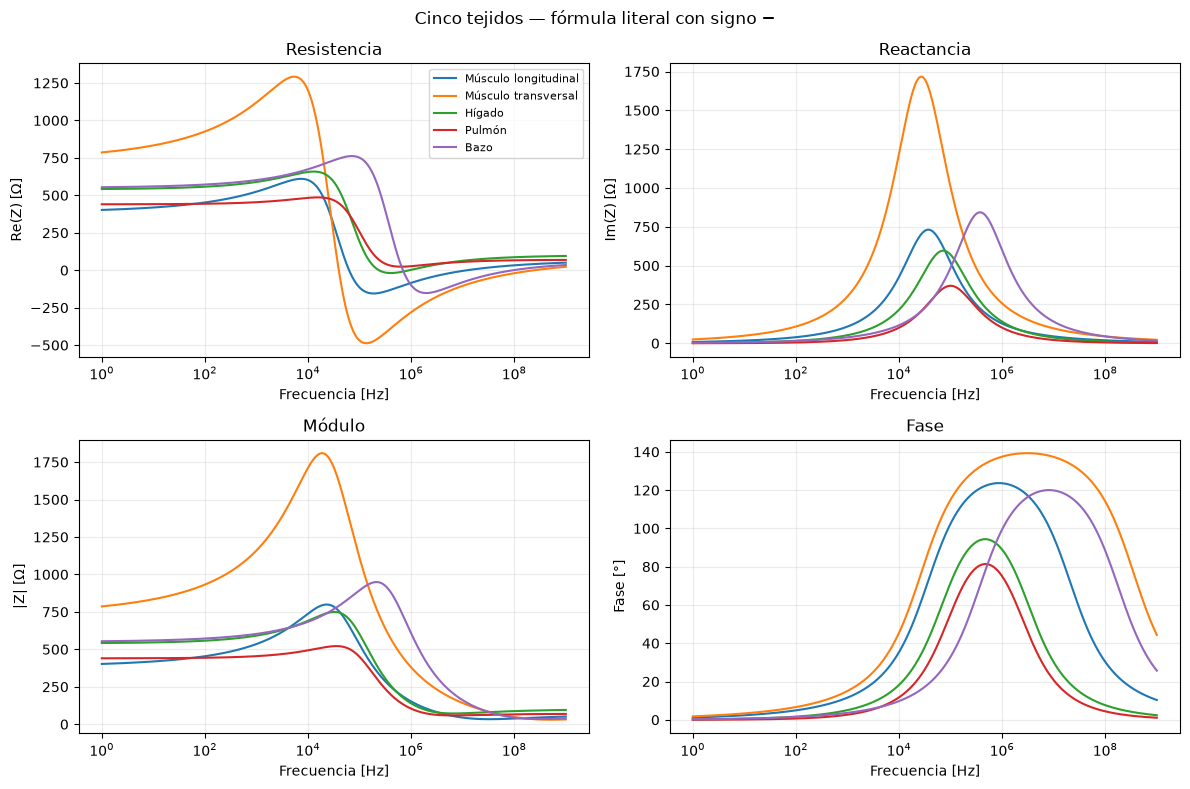

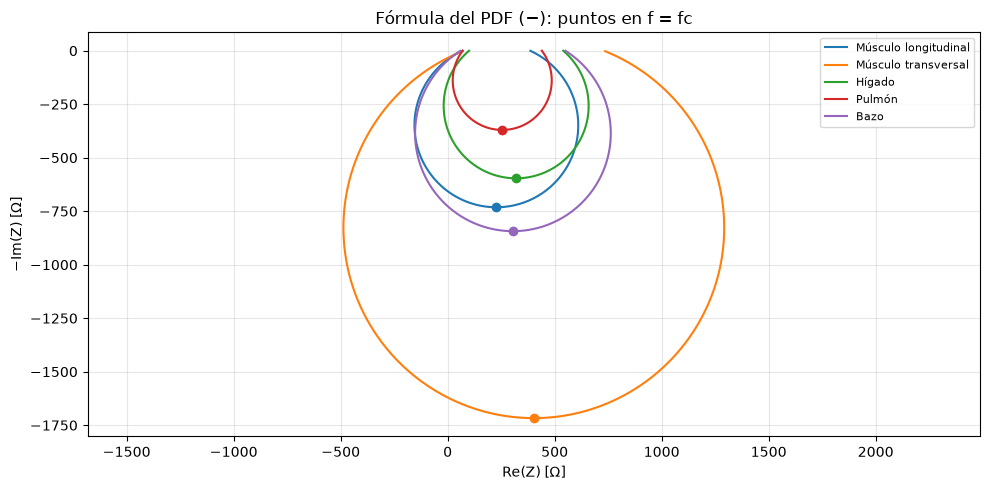

In [ ]:
tejidos = tp.TEJIDOS.copy()
tejidos['tau_us'] = 1e6/(2*np.pi*tejidos.fc_kHz*1000)
display(tejidos)
fig, simulaciones = tp.simular_tejidos()  # signo menos del PDF
simulaciones.to_csv(BASE/'resultados/simulaciones_literal.csv', index=False)
plt.show()
fig = tp.graficar_nyquist()
plt.show()

### Comparación opcional con signo más

Esta figura permite ver la diferencia con la bibliografía. Los cálculos principales usan el signo menos del PDF.

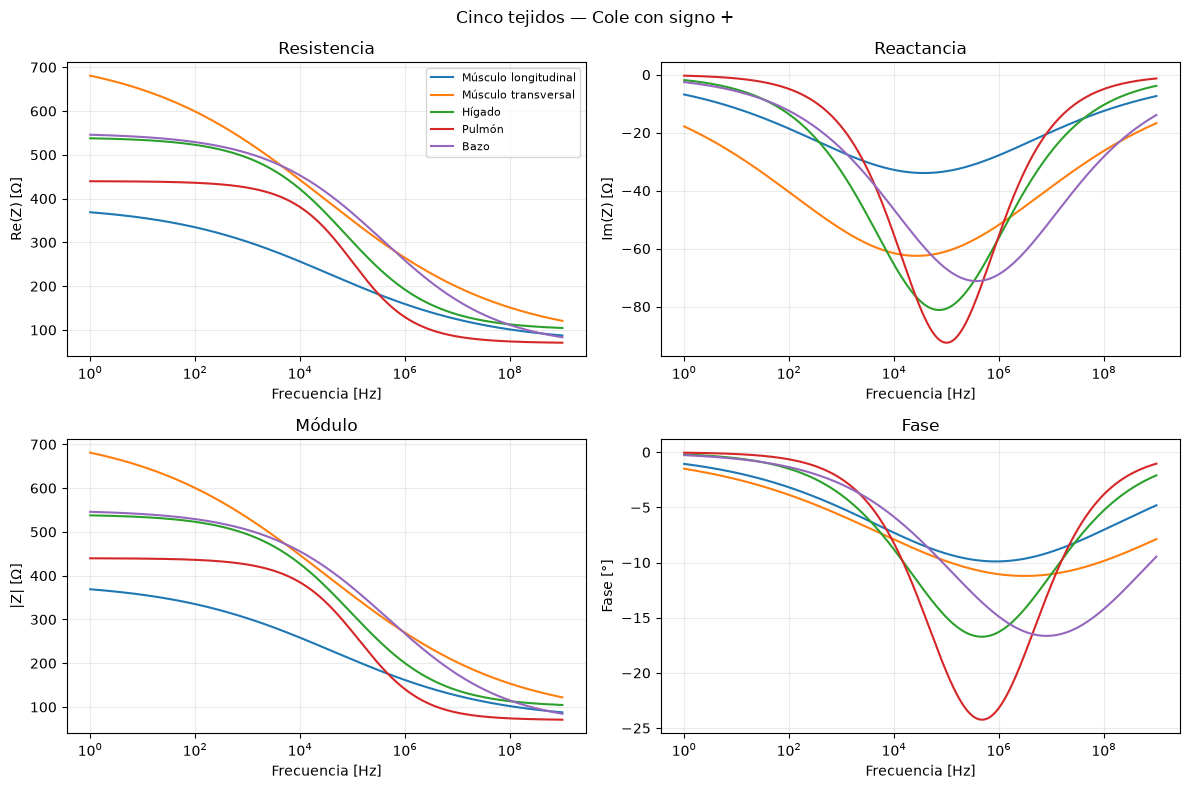

In [ ]:
fig, comparacion = tp.simular_tejidos(signo=1)
comparacion.to_csv(BASE/'resultados/simulaciones_cole.csv', index=False)
plt.show()

## Punto 3: Ajuste de mediciones experimentales con la fórmula del PDF

### Fuente y selección

Se utiliza `registros_EIS.mat` del registro de Zenodo indicado en la consigna, DOI `10.5281/zenodo.15795175`. La versión publicada es de 2025, aunque el texto del punto 3 menciona 2024. Se guardaron los archivos originales y los metadatos; se verifican sus checksums MD5 antes de cargarlos. La base contiene 1457 registros.

Se eligieron los registros 001, 025 y 050 del grupo humano de Ayllón et al., medidos con SFB7 Impedimed y configuración tetrapolar. Representan el comienzo, una posición intermedia y el final del grupo 001–050, que la documentación identifica como libre de errores introducidos. No se supone que sean personas diferentes: los metadatos no lo establecen. También se eligió ID1311, un fantoma de agar medido con Solartron en configuración bipolar. El fantoma es un material de ensayo y no un tejido humano.

Los registros se conservaron al adoptar la fórmula del PDF, para mostrar su compatibilidad real con esos datos. No se buscaron otros registros que ocultaran las discrepancias.

### Preparación y unidades

Las cinco columnas de `eis` son eje frecuencial, parte real, parte imaginaria, módulo y fase. Se usan las tres primeras; las otras dos son derivadas de las componentes complejas.

En los registros 001, 025 y 050 el eje original va de 19377 a 6283200. El rango declarado es 3 kHz–1 MHz. Se interpreta ese eje como frecuencia angular y se divide por $2\pi$, obteniendo aproximadamente 3083.95 Hz–1000002.34 Hz. Es una inferencia por consistencia con el rango declarado, porque el README no explicita la unidad. Si el eje se interpretara como Hz, el $f_c$ estimado se multiplicaría por $2\pi$ y $\tau$ se dividiría por ese factor; los demás parámetros y los errores serían iguales.

En ID1311 el eje 1–65000 es compatible directamente con Hz. No se aplica una conversión global a toda la base.

Se ordenan las frecuencias y se verifica que sean positivas y los datos finitos. No hubo puntos descartados en estos cuatro registros. **No se cambia el signo de la reactancia medida**, no se toman valores absolutos y no se recorta la banda para mejorar el ajuste.

### Criterio de ajuste

Se minimiza conjuntamente el error en la parte real e imaginaria con `scipy.optimize.least_squares`:

$$S(\mathbf p)=\sum_i\left[(\operatorname{Re}Z(f_i;\mathbf p)-R_i)^2+(\operatorname{Im}Z(f_i;\mathbf p)-X_i)^2\right],$$

usando exactamente $Z(f)$ con el signo menos del PDF. Se asigna igual peso en ohmios a todas las componentes, al no disponer de incertidumbre instrumental por punto. La normalización por una escala global sólo mejora el cálculo numérico y no cambia el mínimo.

Se optimizan $\log R_\infty$, $\log(R_0-R_\infty)$ y $\log f_c$, además de $\alpha$. Las resistencias internas se restringen entre $10^{-6}$ y $10^8$ Ω, $f_c$ entre $f_{\min}/100$ y $100f_{\max}$, y $0.01\leq\alpha\leq1$. Se usan 15 inicios por registro: cinco frecuencias iniciales combinadas con $\alpha=0.35,0.7,0.95$, y se conserva el menor costo entre soluciones convergentes.



In [ ]:
registros = tp.cargar_datos()
print('Checksums originales correctos. Registros:', len(registros))
inventario = []
for r in registros:
    if r['id'] in tp.IDS:
        f, z, conversion, descartados = tp.preparar_registro(r)
        np.testing.assert_allclose(np.abs(r['eis'][:, 1]+1j*r['eis'][:, 2]), r['eis'][:, 3])
        inventario.append({'ID': r['id'], 'N': len(f), 'fmin_Hz': f.min(),
                          'fmax_Hz': f.max(), 'conversion': conversion, 'descartados': descartados})
display(pd.DataFrame(inventario))
resumen, curvas = tp.resolver_ajustes(registros)
display(resumen[['id','signo_modelo','R0_ohm','Rinf_ohm','fc_Hz','tau_s','alpha',
                 'RMSE_complejo_ohm','NRMSE_porcentaje','parametro_en_limite']])

Checksums originales correctos. Registros: 1457


,ID,N,fmin_Hz,fmax_Hz,conversion,descartados
0,001,256,3083.945332,1.000002e+06,rad/s → Hz: eje original / (2π),0
1,025,256,3083.945332,1.000002e+06,rad/s → Hz: eje original / (2π),0
2,050,256,3083.945332,1.000002e+06,rad/s → Hz: eje original / (2π),0
3,1311,50,1.000000,6.500000e+04,Hz: sin conversión,0


,id,signo_modelo,R0_ohm,Rinf_ohm,fc_Hz,tau_s,alpha,RMSE_complejo_ohm,NRMSE_porcentaje,parametro_en_limite
0,001,-1,173.476511,159.535316,47832.505108,0.000003,1.0,25.997072,15.444920,True
1,025,-1,173.763779,159.875998,47291.255932,0.000003,1.0,26.052549,15.451076,True
2,050,-1,304.946385,289.057496,46350.692395,0.000003,1.0,29.631443,9.940115,True
3,1311,-1,107.681175,75.225461,105.478217,0.001509,1.0,24.451789,26.187708,True


### Parámetros obtenidos por el optimizador

| ID | R₀ [Ω] | R∞ [Ω] | fc [Hz] | τ [µs] | α |
| --- | --- | --- | --- | --- | --- |
| 001 | 173.4765 | 159.5353 | 47832.5051 | 3.3273 | 1.000000 |
| 025 | 173.7638 | 159.8760 | 47291.2559 | 3.3654 | 1.000000 |
| 050 | 304.9464 | 289.0575 | 46350.6924 | 3.4337 | 1.000000 |
| 1311 | 107.6812 | 75.2255 | 105.4782 | 1508.8892 | 1.000000 |

**Estos resultados no constituyen una caracterización satisfactoria de las muestras.** En todos los registros, $\alpha$ alcanza el límite superior 1. El optimizador converge a una solución restringida, pero eso no implica que la curva describa los datos. No corresponde presentar esos valores como parámetros físicos confiables de los tejidos.

### Errores y validación

Se informa el RMSE complejo por frecuencia:

$$\mathrm{RMSE}_c=\sqrt{\frac1N\sum_i|Z_{\mathrm{ajuste},i}-Z_{\mathrm{medido},i}|^2},$$

$$\mathrm{NRMSE}=100\frac{\mathrm{RMSE}_c}{\sqrt{\frac1N\sum_i|Z_{\mathrm{medido},i}|^2}}.$$

El RMSE combina ambas componentes y divide por $N$, no por $2N$. Para el control de validación se ajustan frecuencias alternas y se evalúan las restantes. Sólo evalúa interpolación dentro del mismo registro, no otras muestras ni extrapolación.

| ID | RMSE complejo [Ω] | NRMSE [%] | RMSE validación [Ω] | Parámetro en límite |
| --- | --- | --- | --- | --- |
| 001 | 25.9971 | 15.4449 | 25.9823 | True |
| 025 | 26.0525 | 15.4511 | 26.0488 | True |
| 050 | 29.6314 | 9.9401 | 29.6306 | True |
| 1311 | 24.4518 | 26.1877 | 24.2301 | True |

Los errores de validación similares a los de entrenamiento no corrigen una incompatibilidad de modelo. El NRMSE se normaliza por toda la impedancia y puede resultar moderado si la componente resistiva es grande, aun con una reactancia mal representada.

### Por qué no coincide la reactancia

Para $R_0>R_\infty\geq0$, $f>0$ y $0<\alpha\leq1$, la fórmula del PDF produce siempre $\operatorname{Im}(Z)>0$. En los tres registros humanos seleccionados la reactancia medida es negativa, y en el fantoma es negativa en casi toda la banda. Ningún ajuste con esos parámetros puede reproducir esa componente. Es una limitación algebraica de la ecuación frente a los datos y a la convención utilizada, no un problema que se resuelva aumentando las iteraciones.

No se invierte el signo experimental para forzar coincidencia ni se atribuye la discrepancia exclusivamente a errores del instrumento. Se mantiene el cálculo literal solicitado y se explicita el resultado.


### Curvas y residuos

Se conserva el signo de la reactancia medida. La falta de coincidencia es parte del resultado del ajuste literal.

### Registro ID001

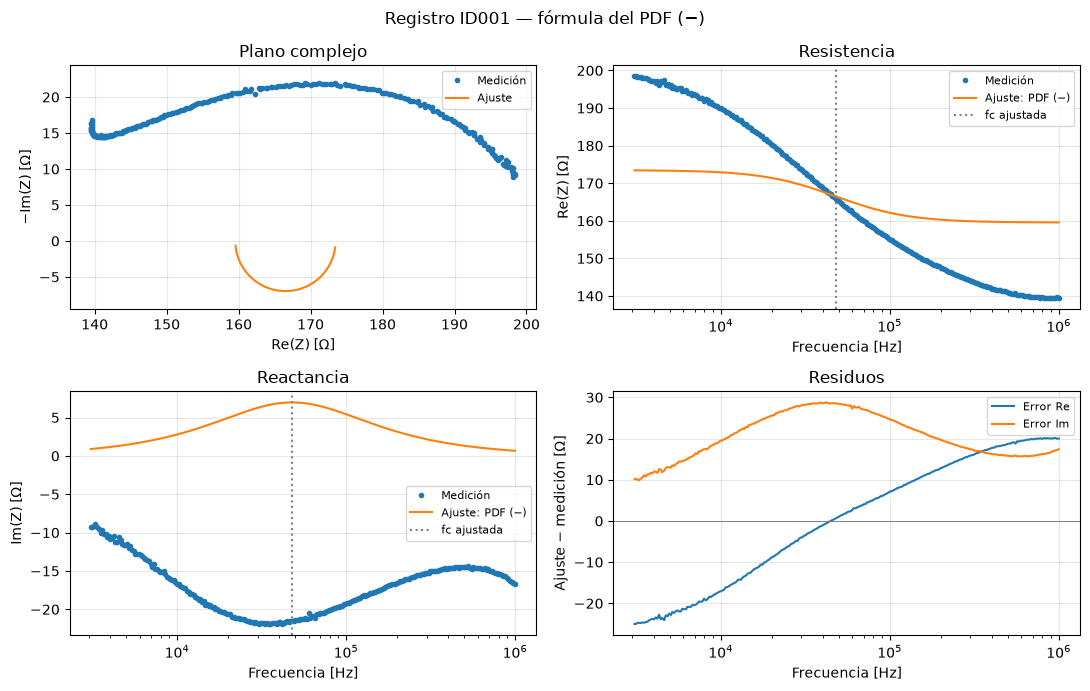

In [ ]:
f, z, parametros = curvas['001']
fig = tp.graficar_ajuste('001', f, z, parametros)
plt.show()

### Registro ID025

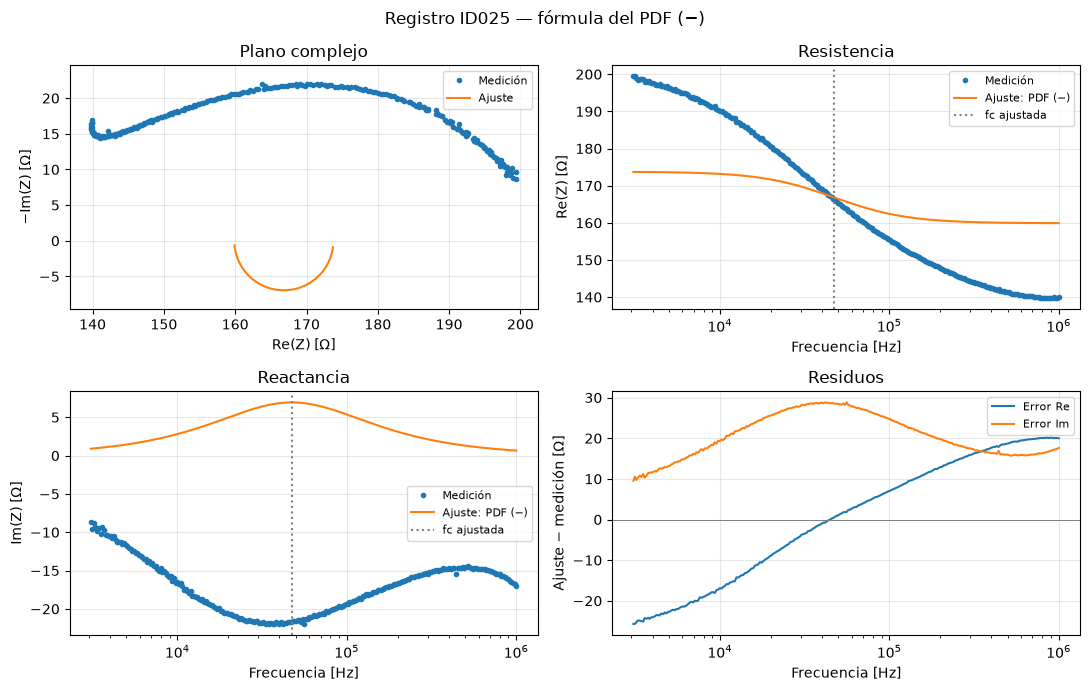

In [ ]:
f, z, parametros = curvas['025']
fig = tp.graficar_ajuste('025', f, z, parametros)
plt.show()

### Registro ID050

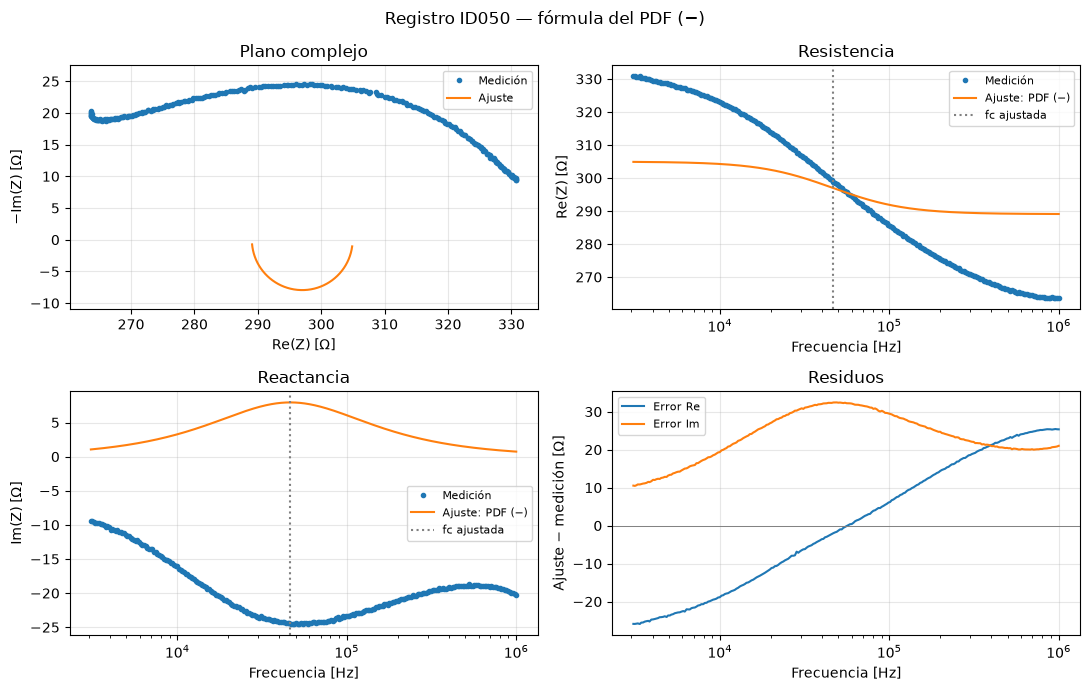

In [ ]:
f, z, parametros = curvas['050']
fig = tp.graficar_ajuste('050', f, z, parametros)
plt.show()

### Registro ID1311

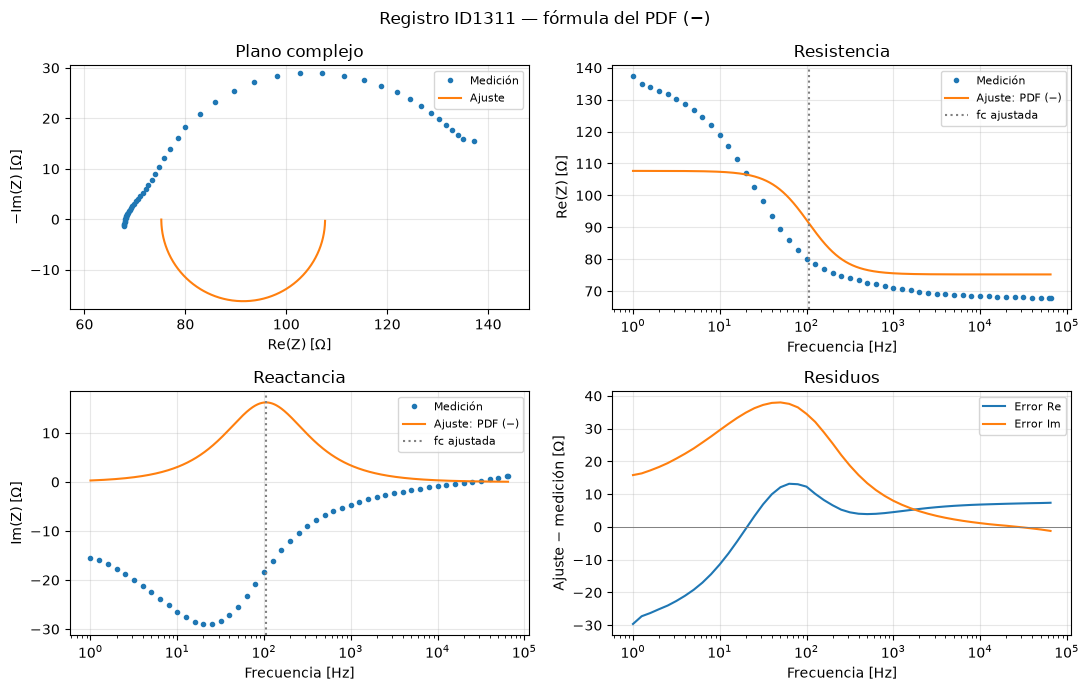

In [ ]:
f, z, parametros = curvas['1311']
fig = tp.graficar_ajuste('1311', f, z, parametros)
plt.show()

### Alcance

Se cumplió el cálculo y la búsqueda de parámetros con la fórmula de la consigna. Para estas mediciones y las restricciones establecidas, no se obtuvo un ajuste físicamente satisfactorio. No se calculan intervalos de confianza ni se interpreta el número de decimales como precisión experimental. Se conserva la discrepancia para poder discutirla a partir de los datos originales y de los signos de la ecuación.


## Conclusiones

Se implementó la fórmula del PDF sin modificar su signo, se compararon los cinco tejidos y se agregó un explorador para mover los parámetros. El cálculo muestra que esta expresión produce reactancia positiva con los parámetros utilizados y puede generar resistencias negativas en algunas bandas.

Se estimaron parámetros por mínimos cuadrados para cuatro registros reales usando esa misma fórmula. Los resultados alcanzan el límite $\alpha=1$ y no reproducen adecuadamente las mediciones, cuya reactancia tiene signo opuesto en la mayor parte o en toda la banda. La convergencia numérica no garantiza un modelo adecuado; esa incompatibilidad debe acompañar la presentación de los parámetros.

## Archivos y reproducción

`Tp6.ipynb` contiene el desarrollo y el explorador; `cole.py` implementa los cálculos y `cole_interactivo.py` los controles. `resultados/` contiene las tablas con las predicciones y residuos recalculados con el signo del PDF. La tabla de parámetros incluye `signo_modelo=-1`. Los datos originales están en `datos/` y no se requiere conexión para repetir el cálculo.

El explorador requiere un kernel activo y `ipywidgets`, ya instalado en el entorno y declarado en `environment.yml`. La forma con signo más se conserva únicamente como comparación explícita; el valor predeterminado de la implementación y del explorador es el menos.

## Referencias

1. Cátedra Modelos y Simulación (2026). *Trabajo Práctico 6*. Consigna local: `../TP6 - MyS - 2026.pdf`.
2. Dell’Osa, A. H., Bravo, N. Y. y Villanueva Jousset, T. (2025). *Single dispersion EIS measurements: a compilation* [Dataset], versión v1. Zenodo. [DOI: 10.5281/zenodo.15795175](https://doi.org/10.5281/zenodo.15795175). Licencia CC BY 4.0 según los metadatos del registro. Archivos originales conservados sin modificar; `Data detail.txt` se guardó como `Data_detail.txt`.
3. Freeborn et al. (2021). *Cole-Impedance Model Representations of Right-Side Segmental Arm, Leg, and Full-Body Bioimpedances of Healthy Adults: Comparison of Fractional-Order*. [Artículo, ecuación (1)](https://www.mdpi.com/2504-3110/5/1/13). Referencia para contrastar la forma habitual con signo más; en este trabajo se utiliza la del PDF.
